# Phân tích dữ liệu (EDA) và phân tích kết quả

Dữ liệu OHLCV từ Binance public API qua `ccxt` (chỉ dùng cho mục đích học tập). Notebook này trả lời 3 câu hỏi cho báo cáo:
1. Return của crypto có phân phối như thế nào?
2. Return có tự tương quan không, tức là có thể dự đoán được không?
3. Phí giao dịch ảnh hưởng tới chiến lược như thế nào?

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from cq.data import load_ohlcv
from cq.features import build_features
from cq.labels import make_dataset
from cq.pipeline import load_config, run_all
cfg = load_config()
plt.rcParams['figure.figsize'] = (11, 4)
data = {s: load_ohlcv(s, '1d', cfg['since'], cfg['exchange']) for s in cfg['symbols']}
{s: (d.index[0].date(), d.index[-1].date(), len(d)) for s, d in data.items()}

{'BTC/USDT': (datetime.date(2019, 1, 1), datetime.date(2026, 11, 11), 2872),
 'ETH/USDT': (datetime.date(2019, 1, 1), datetime.date(2026, 11, 11), 2872),
 'SOL/USDT': (datetime.date(2020, 8, 11), datetime.date(2026, 11, 11), 2284)}

## 1. Giá và phân phối return

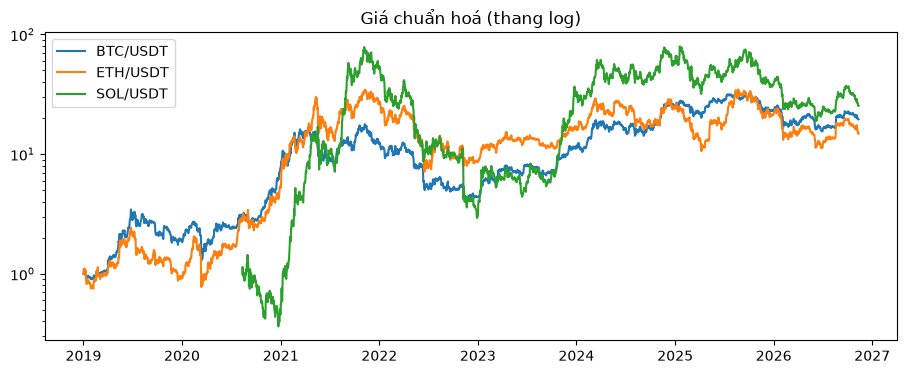

In [2]:
fig, ax = plt.subplots()
for s, d in data.items():
    ax.plot(d['close'] / d['close'].iloc[0], label=s)
ax.set_yscale('log'); ax.set_title('Giá chuẩn hoá (thang log)'); ax.legend(); plt.show()

In [3]:
rets = pd.DataFrame({s: np.log(d['close']).diff() for s, d in data.items()})
stats = pd.DataFrame({'mean': rets.mean(), 'std': rets.std(), 'skew': rets.skew(),
                      'kurtosis': rets.kurt(), 'up_rate': (rets > 0)[rets.notna()].mean()})
stats.round(4)

,mean,std,skew,kurtosis,up_rate
BTC/USDT,0.0010,0.0324,-1.2646,23.4285,0.509579
ETH/USDT,0.0009,0.0426,-1.0492,16.8174,0.514803
SOL/USDT,0.0014,0.0590,-0.2067,8.5349,0.496277


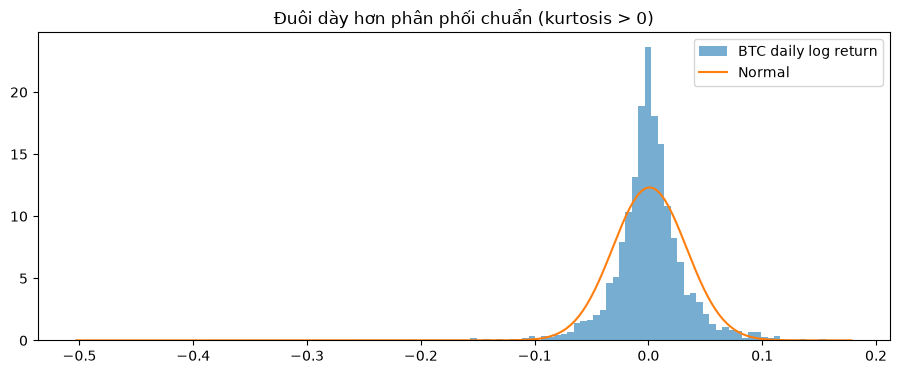

In [4]:
r = rets['BTC/USDT'].dropna()
x = np.linspace(r.min(), r.max(), 200)
plt.hist(r, bins=120, density=True, alpha=.6, label='BTC daily log return')
plt.plot(x, np.exp(-(x - r.mean())**2 / (2 * r.var())) / np.sqrt(2 * np.pi * r.var()), label='Normal')
plt.legend(); plt.title('Đuôi dày hơn phân phối chuẩn (kurtosis > 0)'); plt.show()

**Nhận xét:** tỷ lệ ngày tăng khoảng 50%, nên bài toán phân loại gần như cân bằng và accuracy 50% là mức ngẫu nhiên. Kurtosis lớn cho thấy có nhiều biến động cực đoan, đó là lý do các model rủi ro cao dễ bị drawdown lớn.

## 2. Tự tương quan

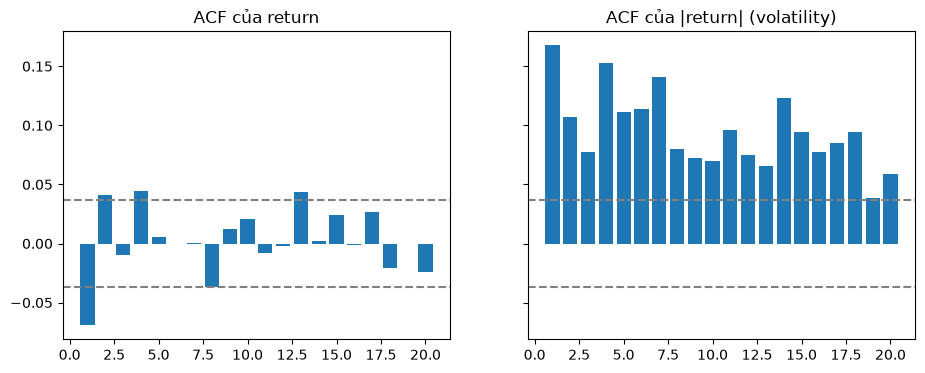

In [5]:
def acf(s, lags=20):
    return [s.autocorr(k) for k in range(1, lags + 1)]
fig, axes = plt.subplots(1, 2, sharey=True)
conf = 1.96 / np.sqrt(len(r))
for ax, series, title in ((axes[0], r, 'ACF của return'), (axes[1], r.abs(), 'ACF của |return| (volatility)')):
    ax.bar(range(1, 21), acf(series)); ax.axhline(conf, ls='--', c='gray'); ax.axhline(-conf, ls='--', c='gray')
    ax.set_title(title)
plt.show()

**Nhận xét:** tự tương quan của return gần như nằm trong dải tin cậy, tức hướng giá rất khó dự đoán (gần với giả thuyết thị trường hiệu quả). Ngược lại, |return| có tự tương quan rõ (volatility clustering), nên các feature về volatility có ích để biết lúc nào thị trường biến động mạnh.

## 3. Tương quan giữa feature và nhãn

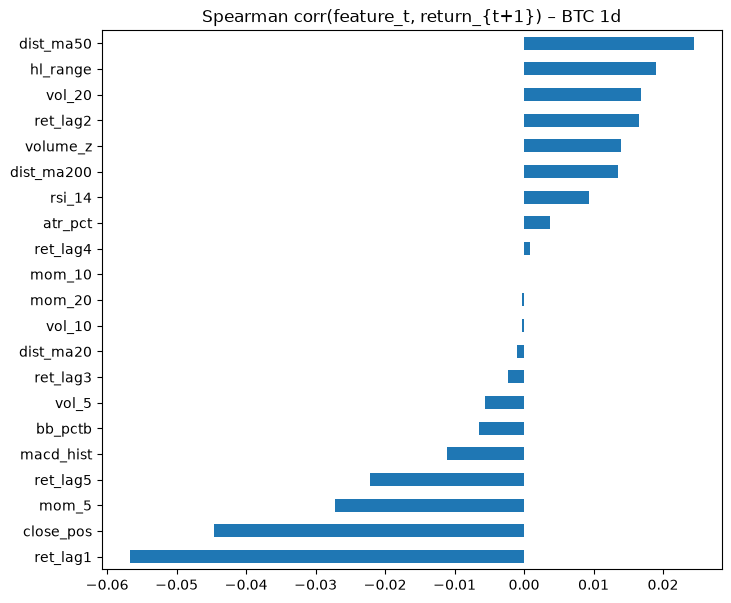

In [6]:
d = data['BTC/USDT']
X, y, fwd = make_dataset(build_features(d), d['close'])
X.corrwith(fwd, method='spearman').sort_values().plot.barh(figsize=(8, 7), title='Spearman corr(feature_t, return_{t+1}) – BTC 1d')
plt.show()

## 4. Tác động của phí: v1 (ban đầu) và v2 (cải tiến)

**v1**: nhãn 1 nến, vào khi p > 0.5, thoát khi p < 0.5. **v2**: nhãn 3 nến (bớt nhiễu) + vùng đệm ±0.05 (vào khi p > 0.55, thoát khi p < 0.45). Cấu hình v2 được chọn chỉ trên dữ liệu trước 2025.

In [7]:
rows = []
for name, kw in {'v1': dict(horizon=1, band=0.0), 'v2': dict(horizon=3, band=0.05)}.items():
    for fee in [0.0, 0.0002, 0.0005, 0.001]:
        t, _ = run_all('BTC/USDT', '4h', cfg, fee=fee, models=['lightgbm'], **kw)
        rows.append({'version': name, 'fee_%': fee * 100,
                     **t.loc['lightgbm', ['total_return', 'sharpe', 'max_drawdown', 'n_trades']].to_dict()})
fee_tbl = pd.DataFrame(rows).set_index(['version', 'fee_%']); fee_tbl.round(3)

total_return  sharpe  max_drawdown  n_trades
version fee_%                                              
v1      0.00         17.649   1.404        -0.525    5955.0
        0.02          4.667   0.919        -0.585    5955.0
        0.05         -0.051   0.192        -0.665    5955.0
        0.10         -0.952  -1.020        -0.975    5955.0
v2      0.00          9.025   1.067        -0.487     907.0
        0.02          7.361   1.002        -0.501     907.0
        0.05          5.369   0.905        -0.523     907.0
        0.10          3.045   0.742        -0.567     907.0

v1 giao dịch khoảng 6000 lần nên chỉ có lãi khi phí gần bằng 0. v2 giao dịch ít hơn khoảng 10 lần nên chịu được mức phí thực tế.

## 5. Design và holdout (cấu hình v2 mặc định)

In [8]:
from cq.pipeline import period_summary
hs = cfg['holdout_start']
res = []
for tf in cfg['timeframes']:
    for s in cfg['symbols']:
        _, exps = run_all(s, tf, cfg, models=['lightgbm'])
        bts = {m: e.bt for m, e in exps.items()}
        for per, kw in (('design', dict(end=hs)), ('holdout', dict(start=hs))):
            ps = period_summary(bts, tf, **kw)
            for m in ps.index:
                res.append({'pair': f'{s} {tf}', 'period': per, 'model': m, **ps.loc[m, ['total_return', 'sharpe', 'max_drawdown']].to_dict()})
res = pd.DataFrame(res)
res.pivot_table(index=['period', 'pair'], columns='model', values=['sharpe', 'max_drawdown']).round(2)

max_drawdown                sharpe         
model               buy_and_hold lightgbm buy_and_hold lightgbm
period  pair                                                   
design  BTC/USDT 1d        -0.77    -0.69         0.84     0.46
        BTC/USDT 4h        -0.77    -0.57         0.70     1.05
        ETH/USDT 1d        -0.79    -0.72         0.57     0.10
        ETH/USDT 4h        -0.81    -0.62         0.63     0.72
        SOL/USDT 1d        -0.43    -0.35         1.79     1.55
        SOL/USDT 4h        -0.76    -0.62         1.27     1.31
holdout BTC/USDT 1d        -0.53    -0.54        -0.07    -0.00
        BTC/USDT 4h        -0.53    -0.48        -0.08    -0.12
        ETH/USDT 1d        -0.68    -0.44        -0.02     0.66
        ETH/USDT 4h        -0.68    -0.54        -0.07     0.54
        SOL/USDT 1d        -0.76    -0.65        -0.19    -0.34
        SOL/USDT 4h        -0.78    -0.41        -0.22    -0.15

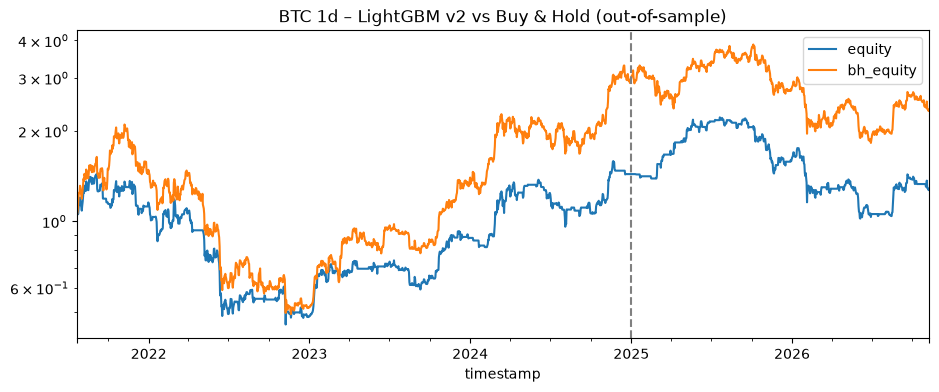

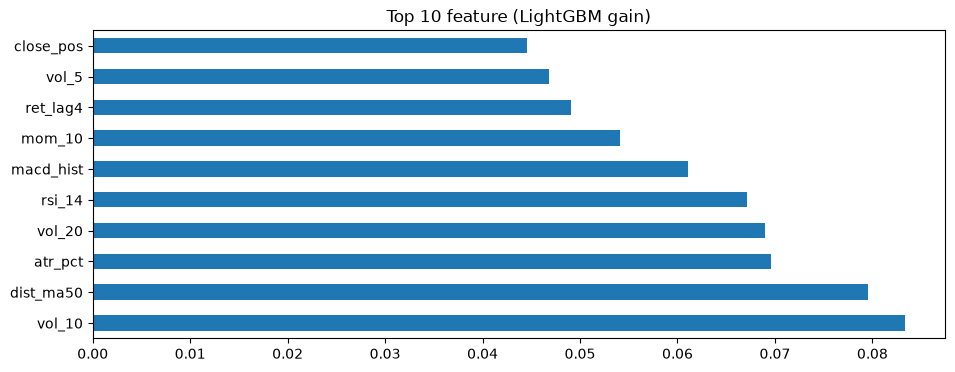

In [9]:
t1d, exps = run_all('BTC/USDT', '1d', cfg)
bt = exps['lightgbm'].bt
ax = bt[['equity', 'bh_equity']].plot(logy=True, title='BTC 1d – LightGBM v2 vs Buy & Hold (out-of-sample)')
ax.axvline(pd.Timestamp(hs, tz='UTC'), ls='--', c='gray'); plt.show()
exps['lightgbm'].wf.importance.head(10).plot.barh(title='Top 10 feature (LightGBM gain)'); plt.show()

## Kết luận

- Accuracy out-of-sample chỉ khoảng 50–55%, AUC khoảng 0.50–0.56: có tín hiệu nhưng rất yếu, đúng với kỳ vọng ở thị trường có tính cạnh tranh cao.
- **Chi phí giao dịch là yếu tố quyết định.** v1 có tín hiệu ở khung 4h nhưng hàng nghìn lần giao dịch làm mất gần hết vốn. Chỉ cần làm nhãn bớt nhiễu (horizon 3) và thêm vùng đệm, số lệnh giảm khoảng 5–10 lần và Sharpe trung bình tăng từ 0.28 lên 0.87 trên giai đoạn design.
- Trên **holdout** 2025–2026 (thị trường giảm, Buy & Hold Sharpe khoảng -0.1), LightGBM v2 có Sharpe +0.10, thắng Buy & Hold ở 4/6 cặp, Max DD trung bình -51% so với -66%.
- Trong giai đoạn tăng mạnh (design), v2 vẫn chưa thắng Buy & Hold một cách ổn định: đứng ngoài thị trường thì bỏ lỡ một phần xu hướng tăng. Lợi ích chính của mô hình là **giảm rủi ro** khi thị trường giảm, không phải tăng lợi nhuận.
- Hạn chế: holdout ngắn (khoảng 22 tháng), chỉ 3 coin và tương quan mạnh với nhau, nên chưa đủ để kết luận chiến lược có lợi thế bền vững.